In [5]:
import numpy as np
import matplotlib.pyplot as plt

CSLIP_init_00.rpt : 80 blocs, dernier bloc = 52 lignes, max |CSLIP| = 0, integrale signee = 0
CSLIP_init_01.rpt : 82 blocs, dernier bloc = 52 lignes, max |CSLIP| = 0.00858205, integrale signee = -0.0205853
CSLIP_centri_00.rpt : 83 blocs, dernier bloc = 52 lignes, max |CSLIP| = 0.00858205, integrale signee = -0.0205853
CSLIP_centri_01.rpt : 84 blocs, dernier bloc = 52 lignes, max |CSLIP| = 0.01364, integrale signee = -0.0338931
CSLIP_centri_02.rpt : 85 blocs, dernier bloc = 52 lignes, max |CSLIP| = 0.018701, integrale signee = -0.0472084
CSLIP_centri_03.rpt : 86 blocs, dernier bloc = 52 lignes, max |CSLIP| = 0.023768, integrale signee = -0.0605421
CSLIP_centri_04.rpt : 88 blocs, dernier bloc = 52 lignes, max |CSLIP| = 0.0288406, integrale signee = -0.0738937
CSLIP_centri_05.rpt : 89 blocs, dernier bloc = 52 lignes, max |CSLIP| = 0.0339166, integrale signee = -0.0872534
CSLIP_centri_06.rpt : 90 blocs, dernier bloc = 52 lignes, max |CSLIP| = 0.0332237, integrale signee = -0.0862121
CSLIP_

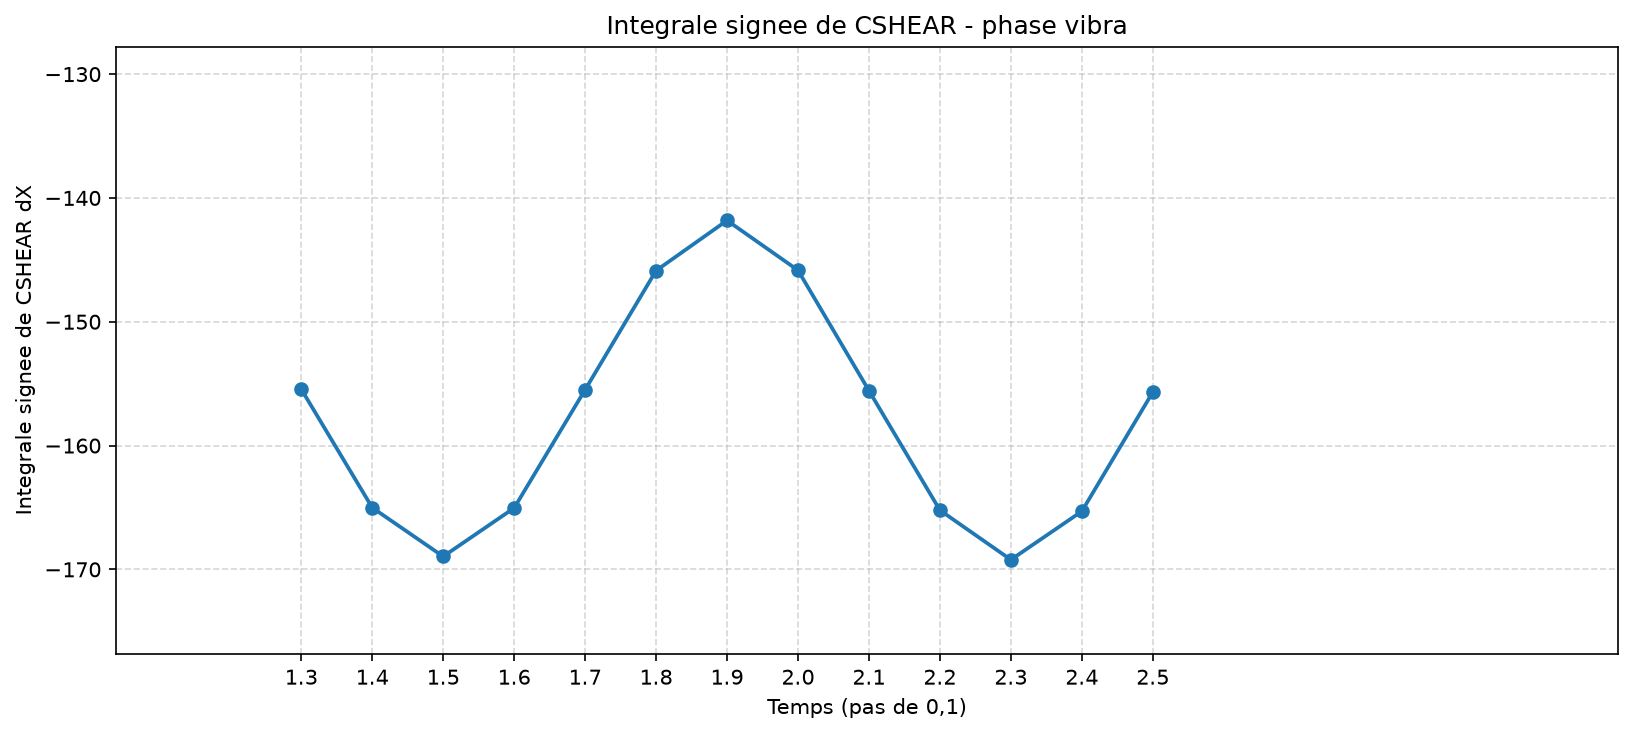

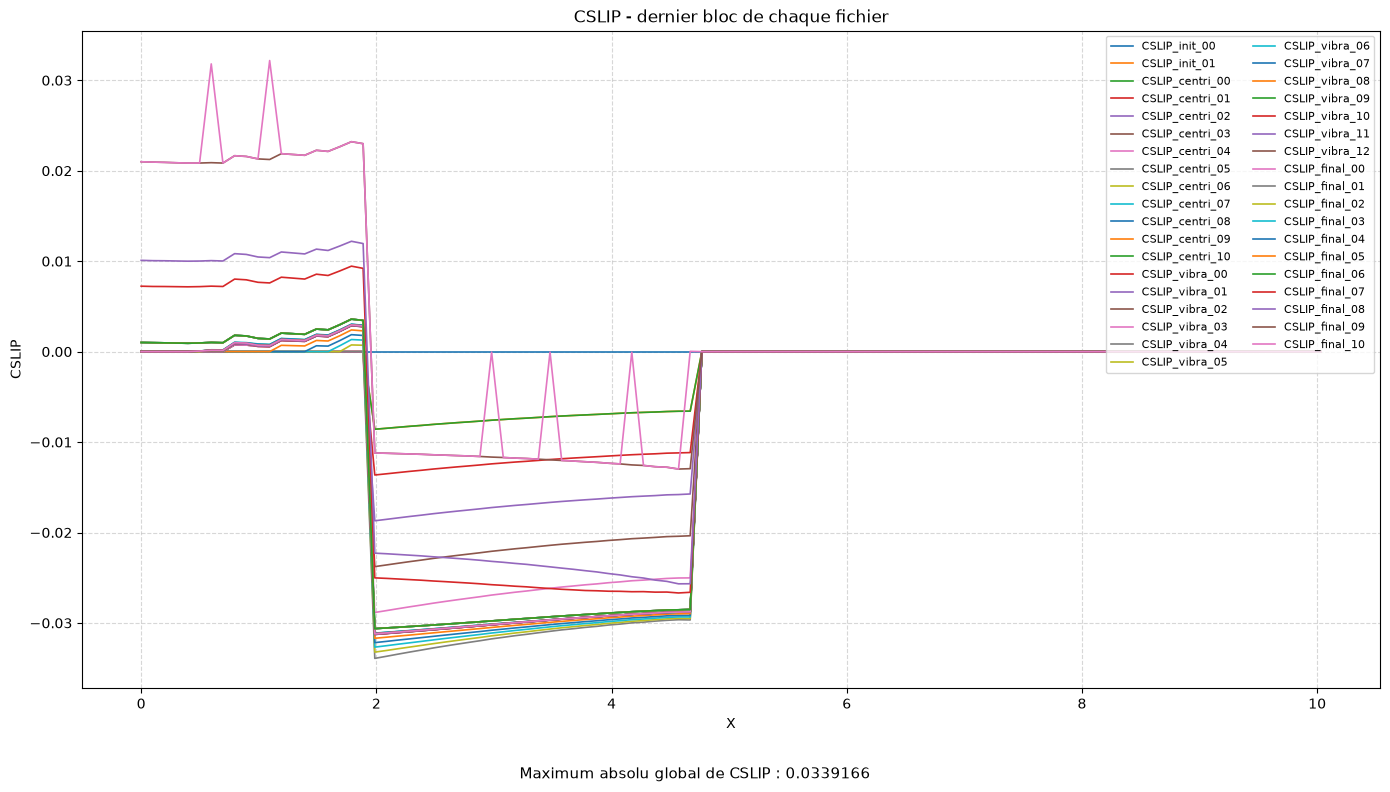

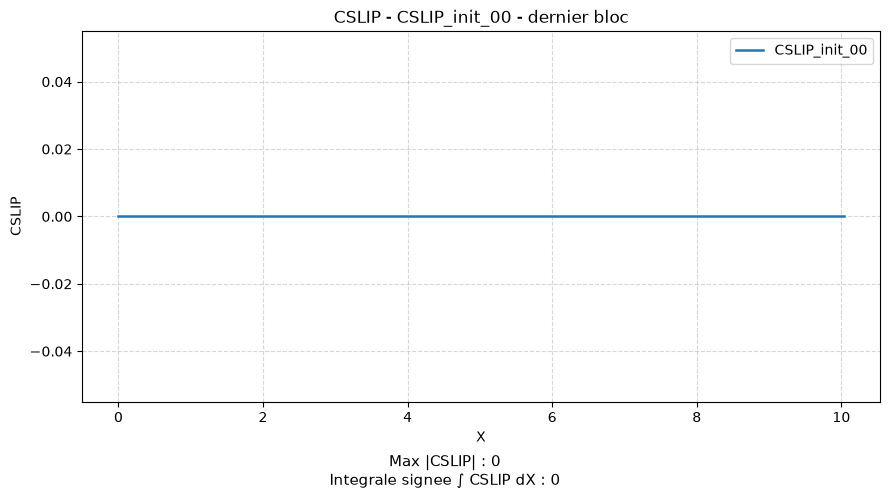

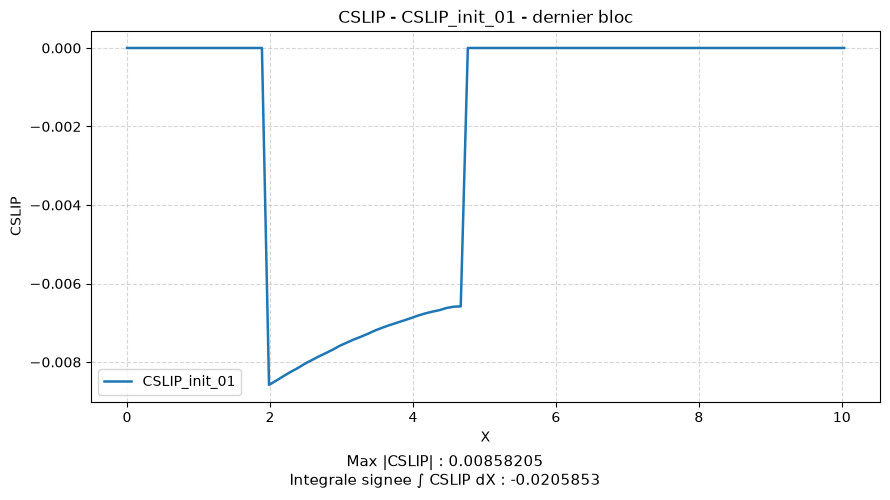

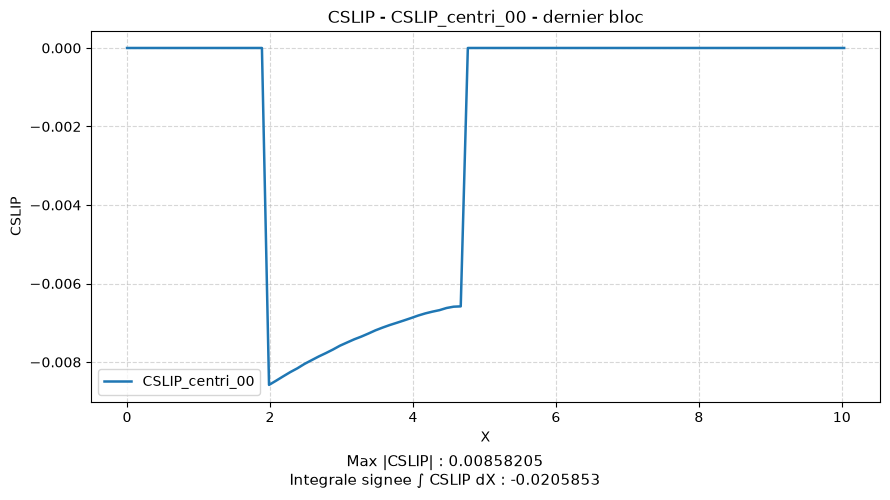

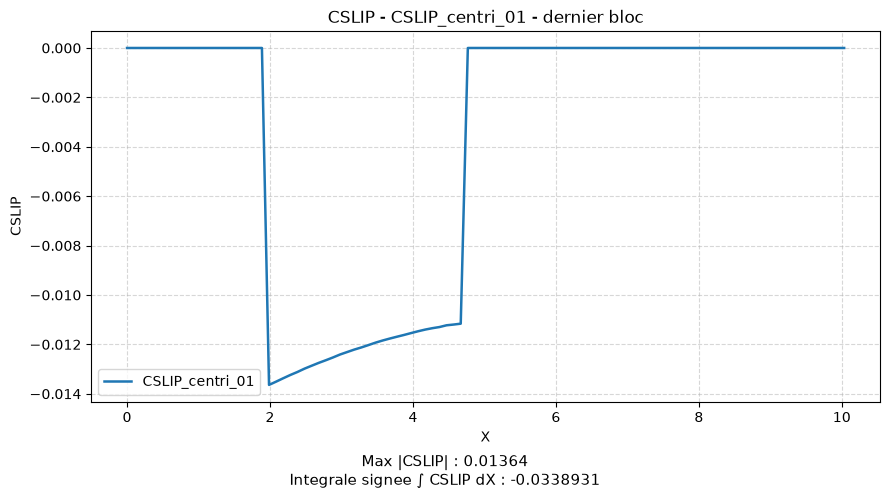

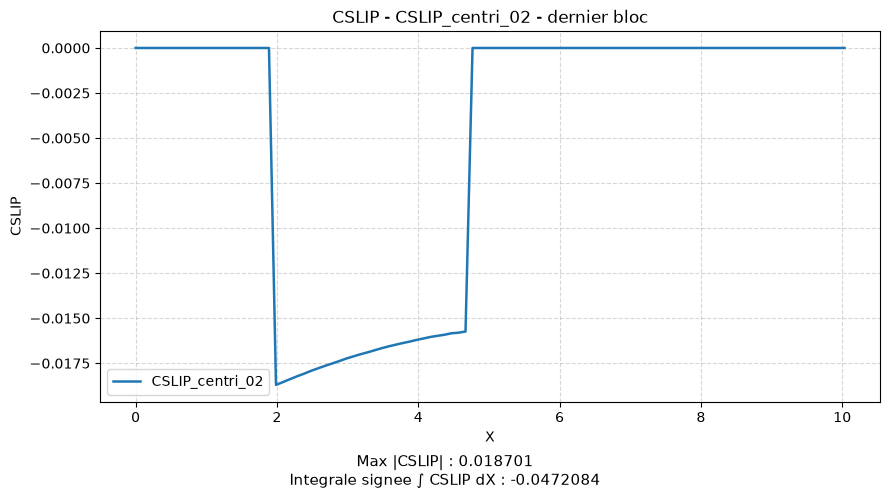

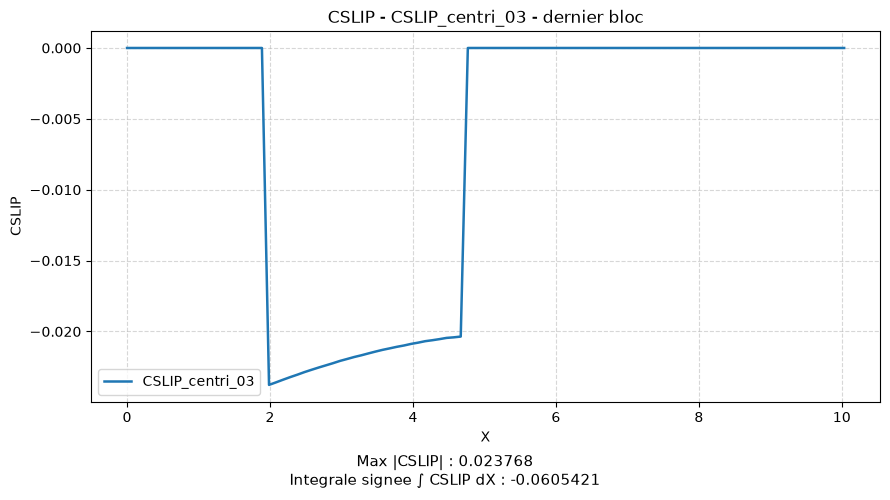

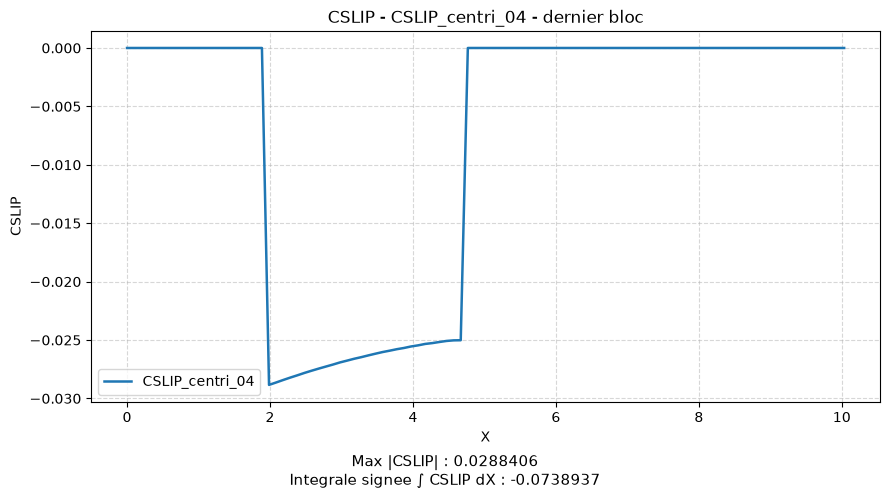

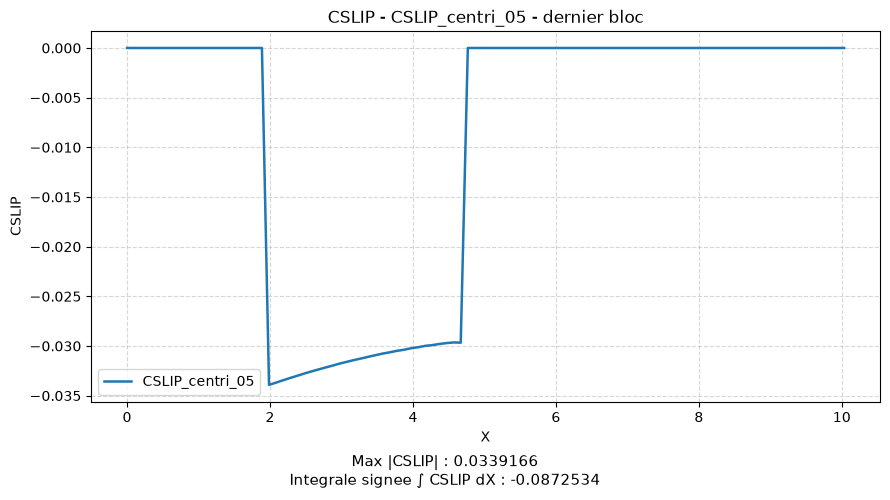

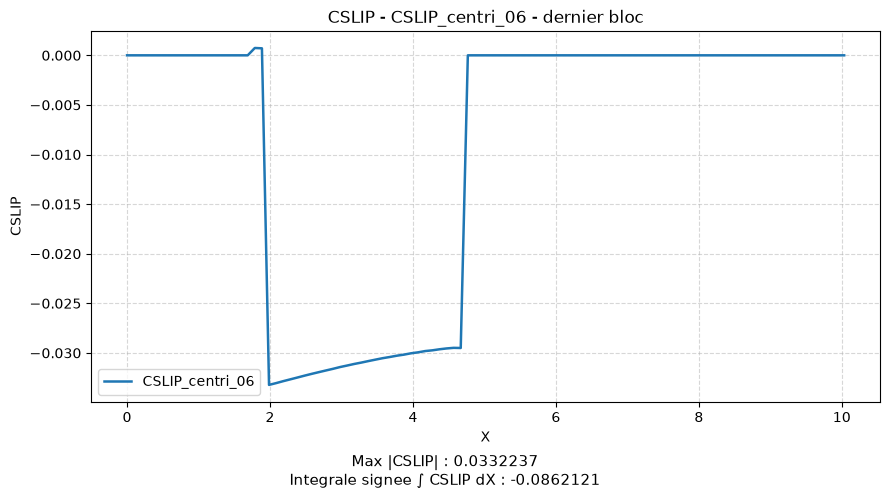

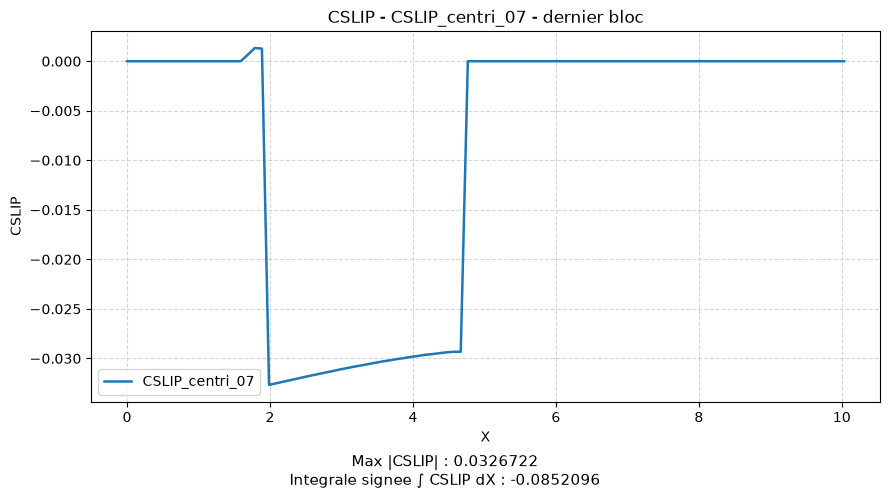

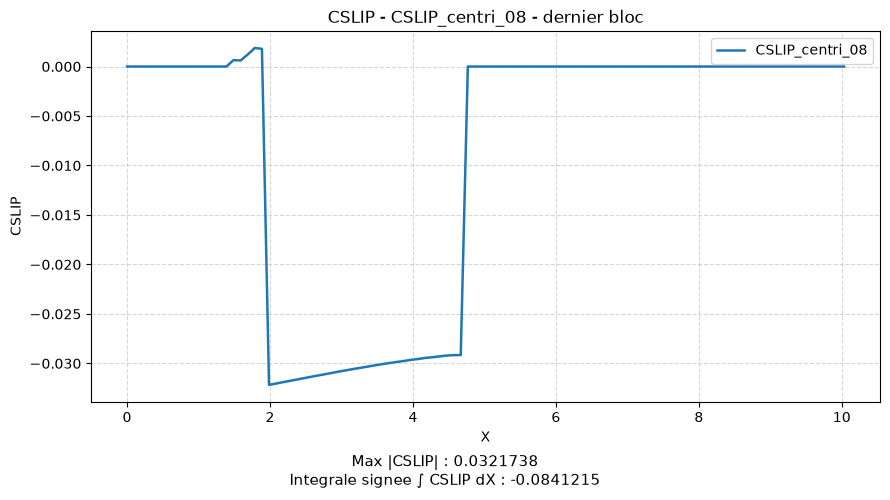

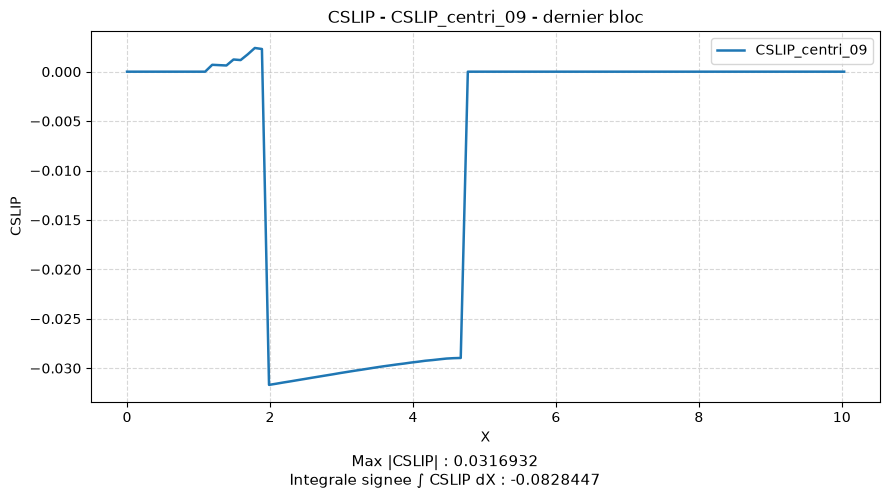

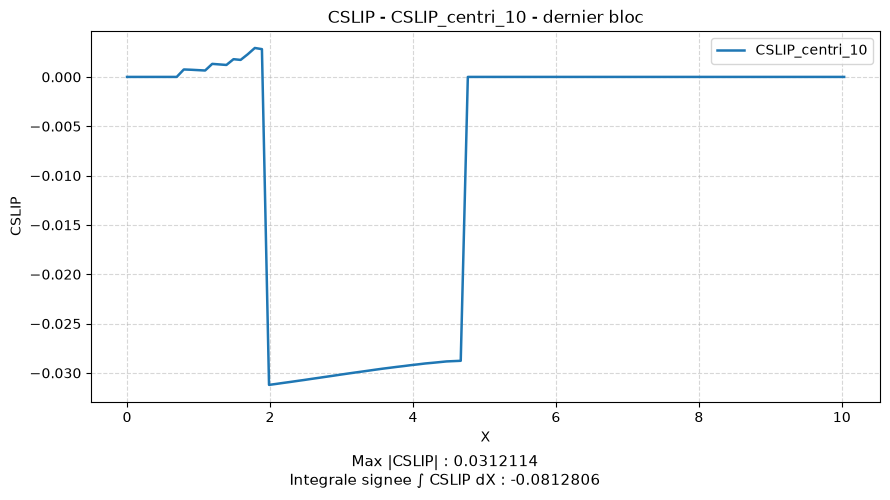

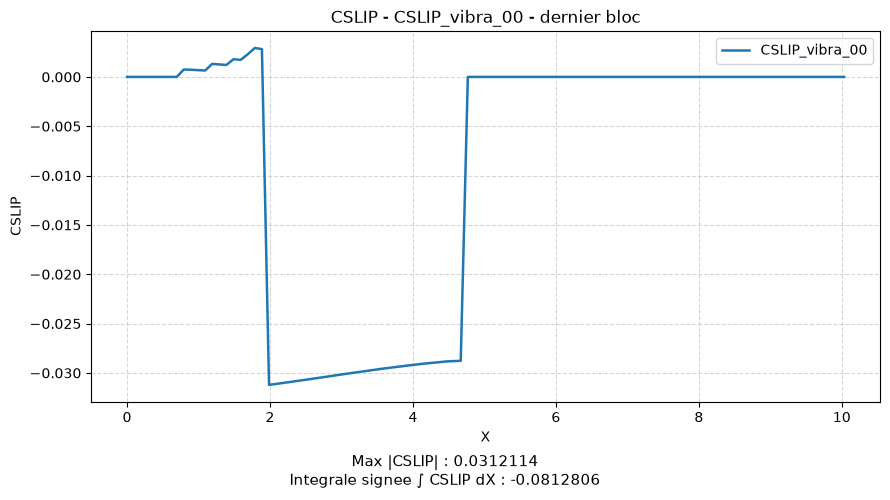

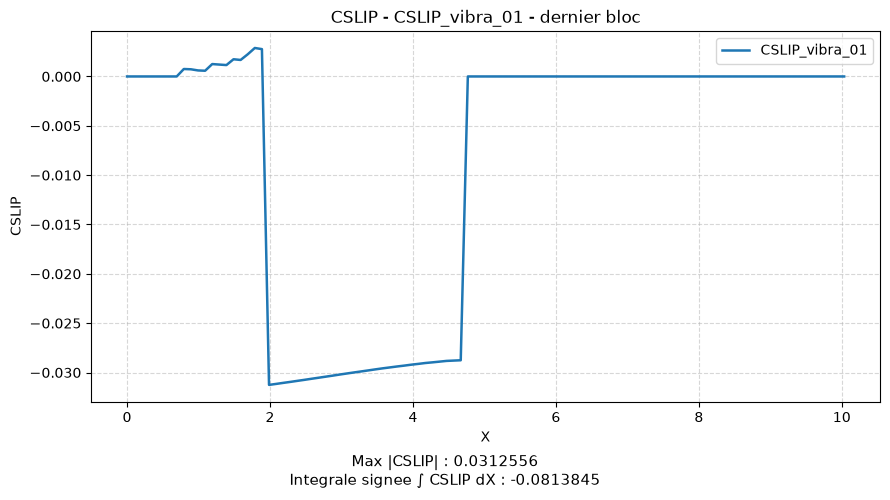

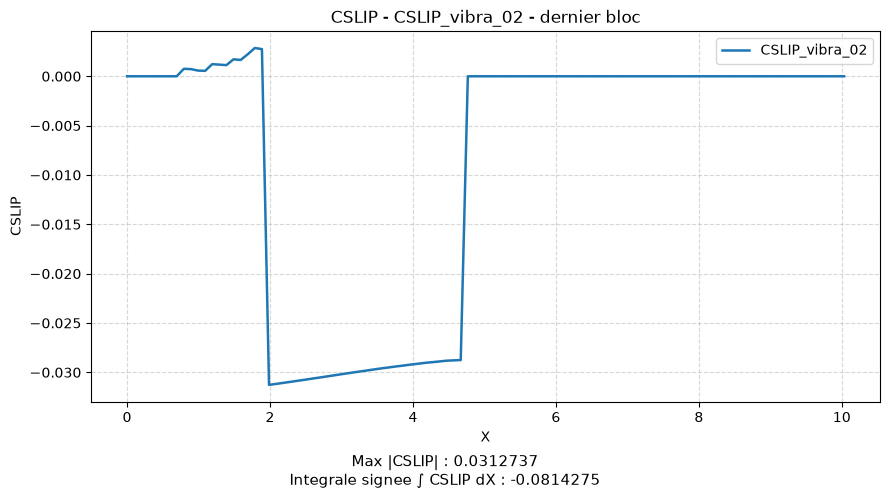

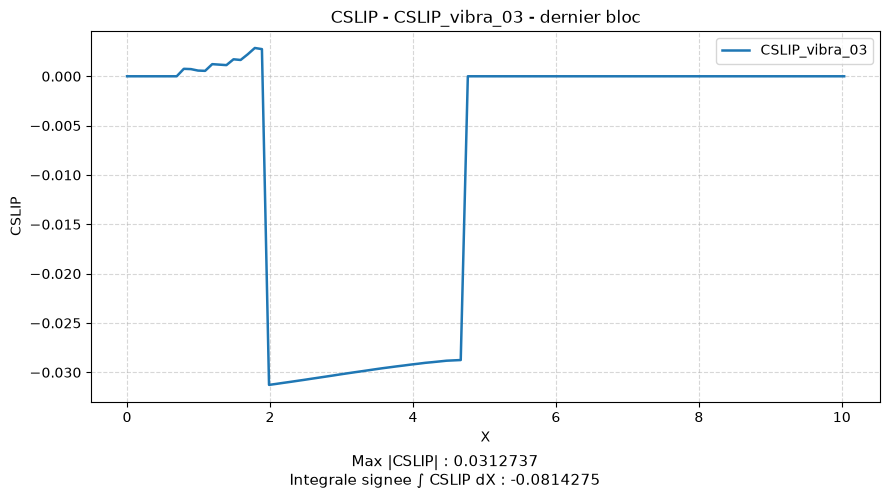

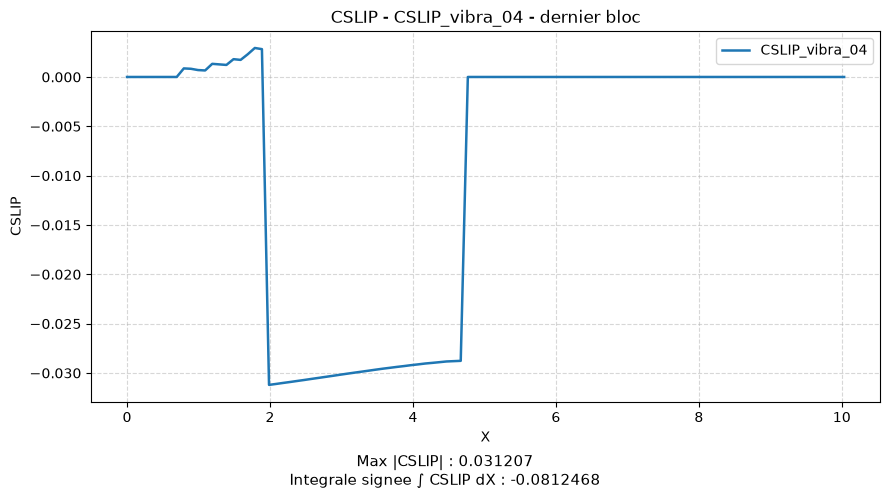

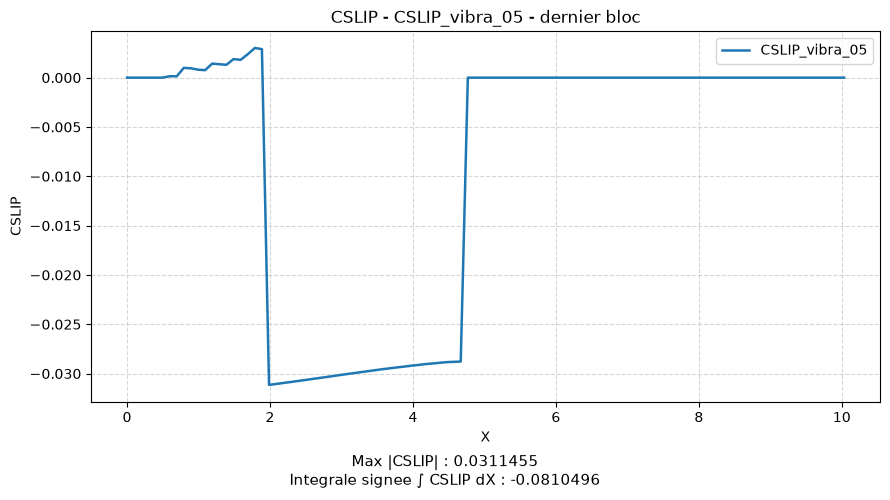

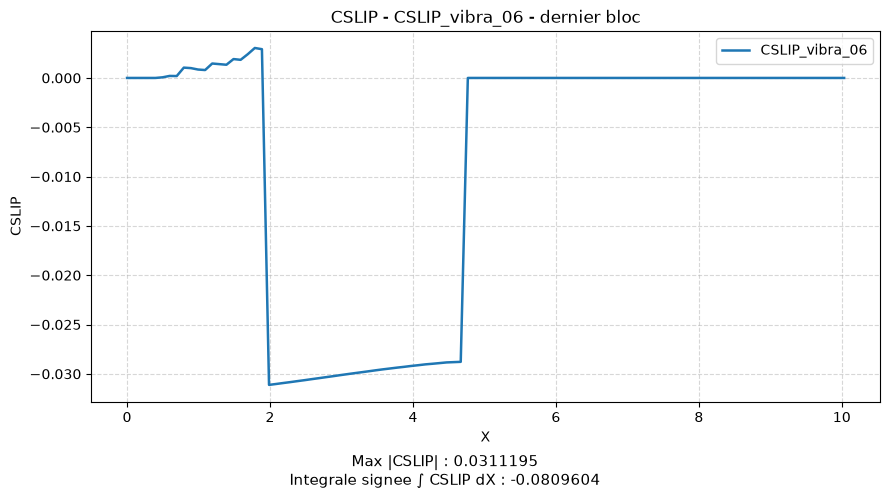

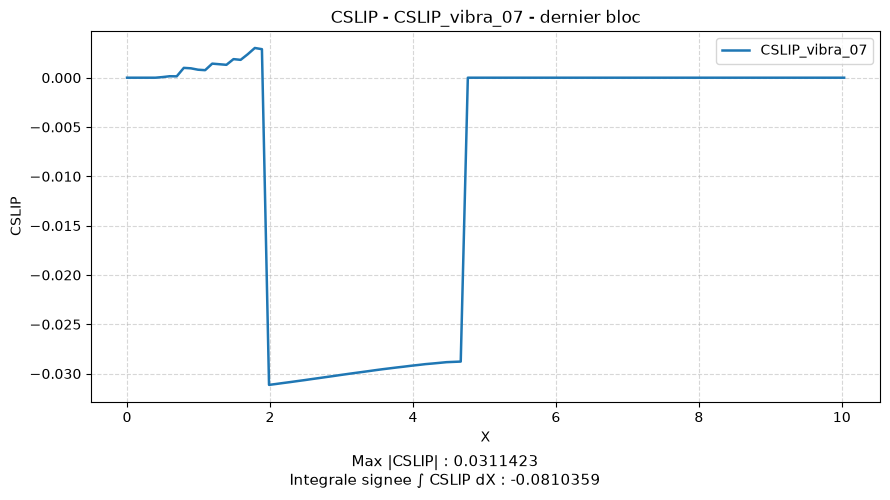

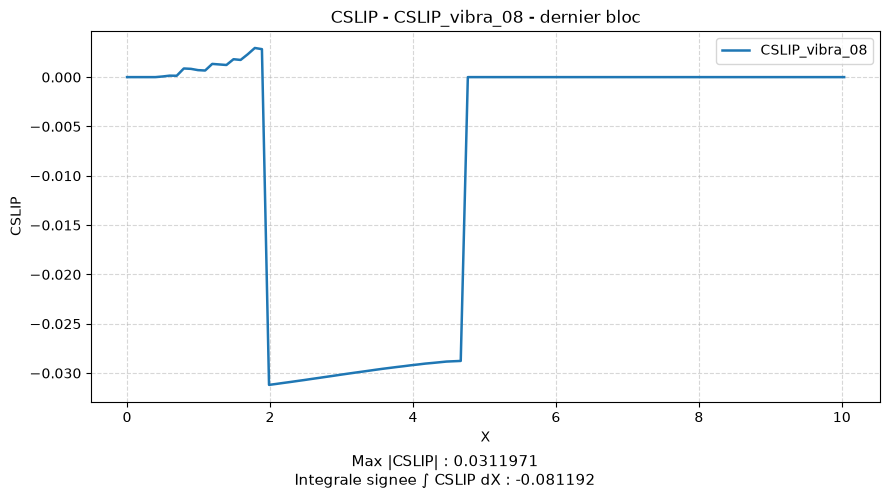

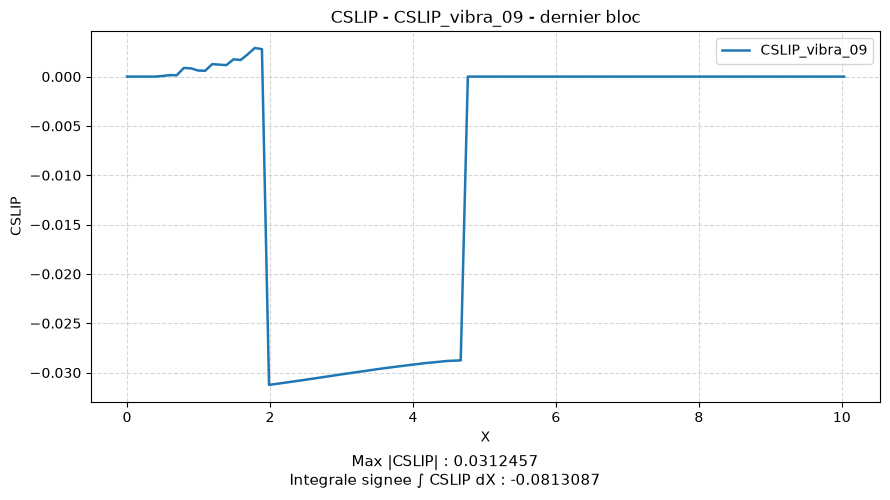

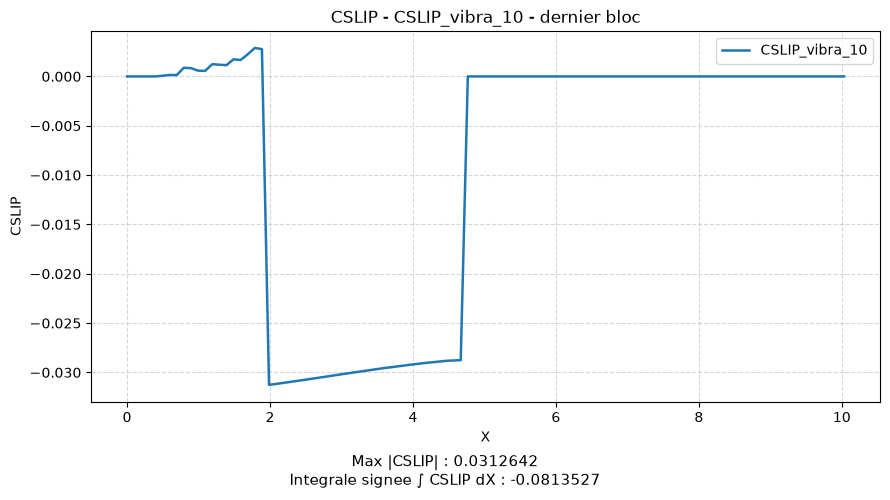

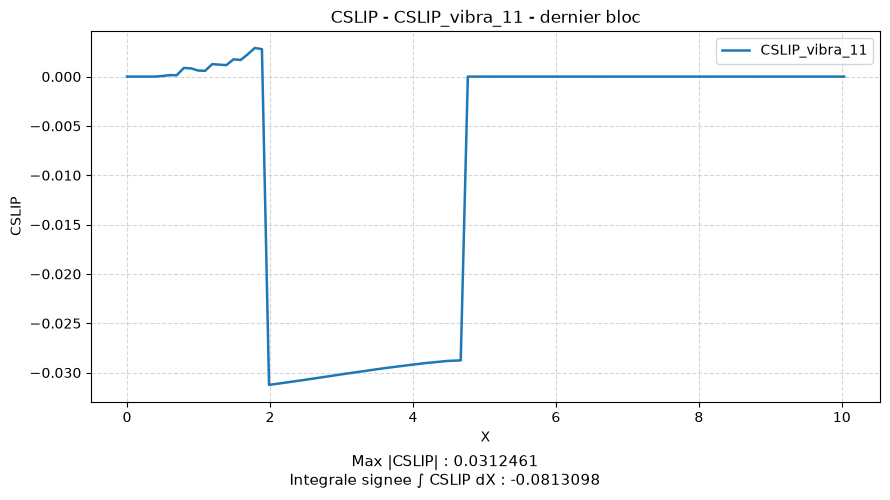

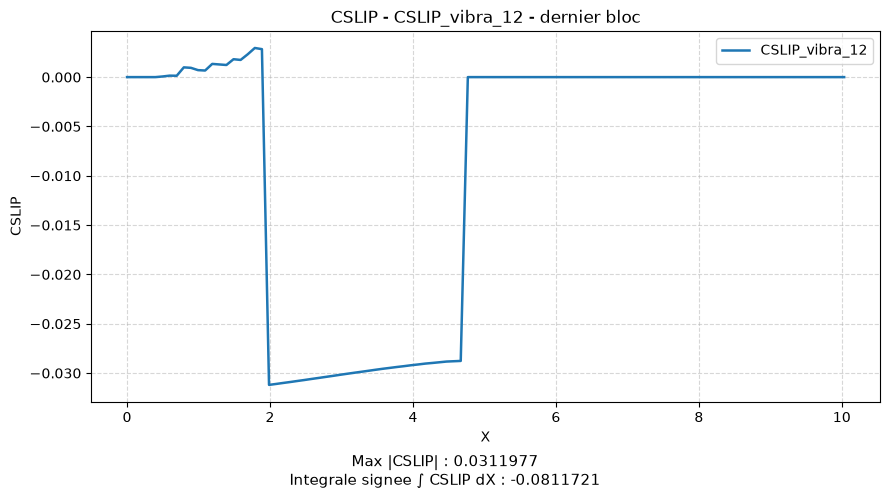

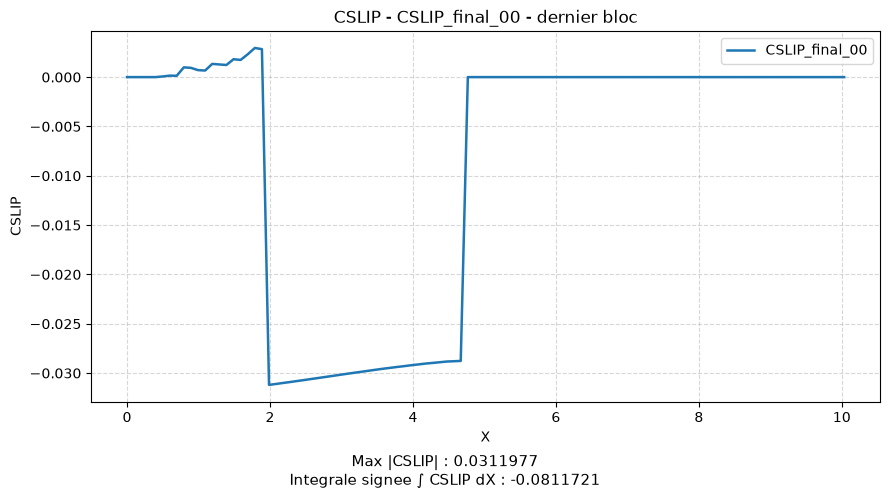

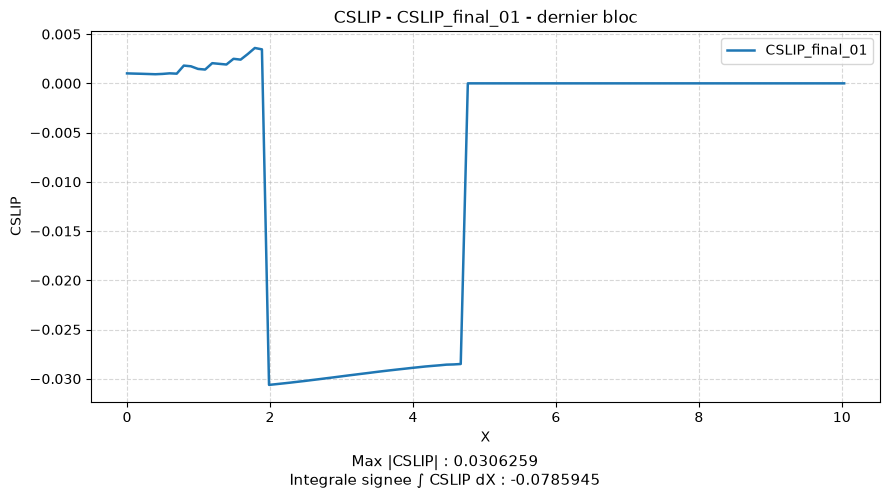

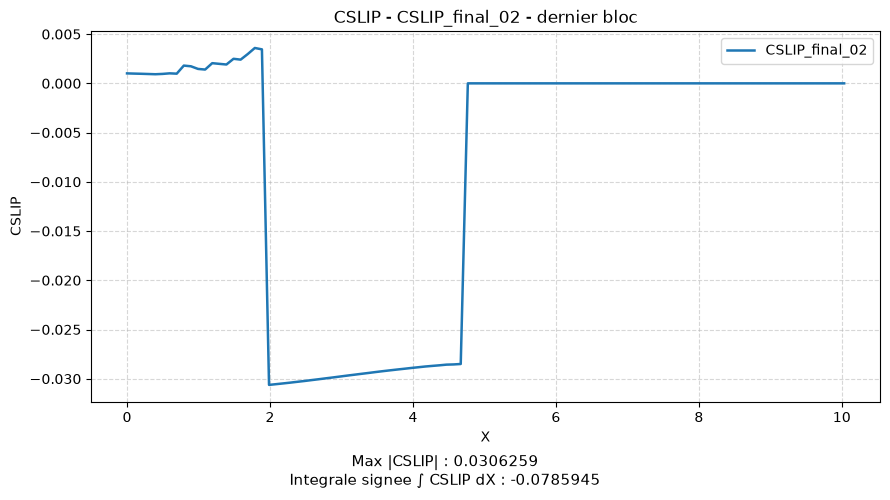

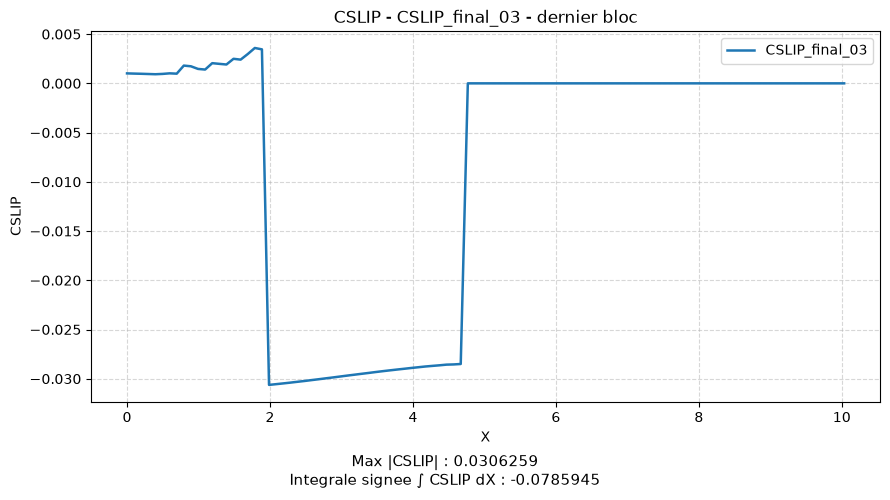

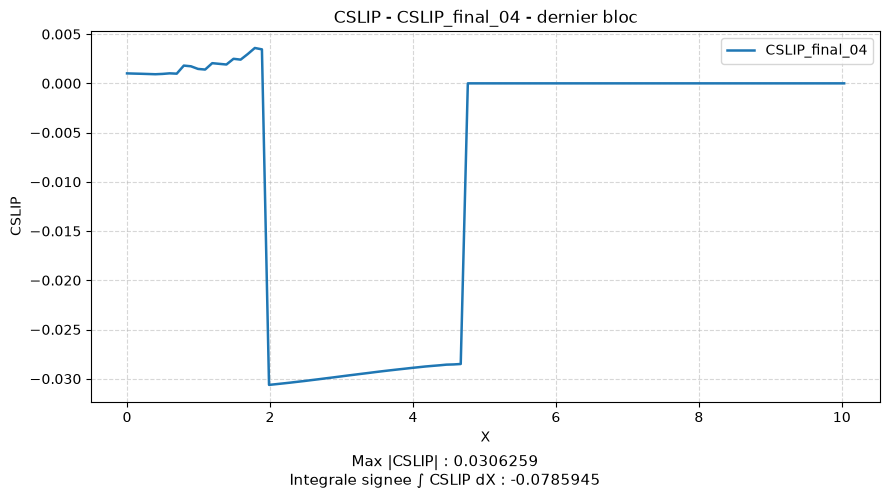

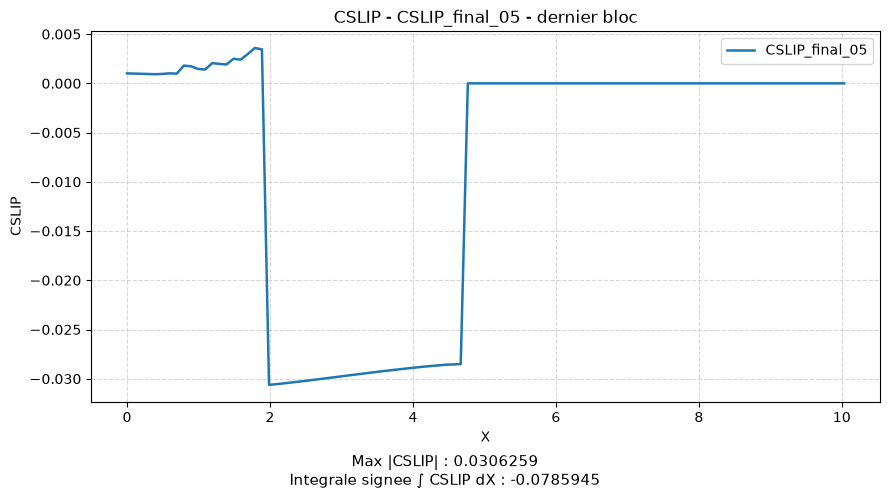

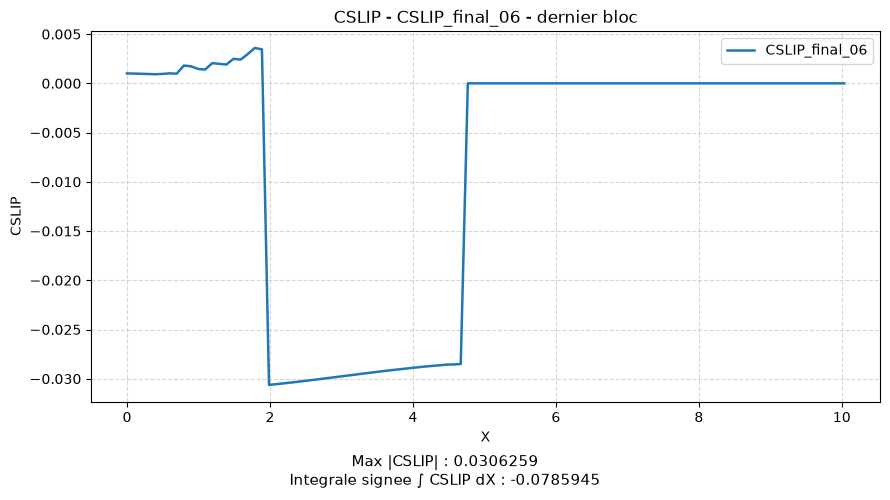

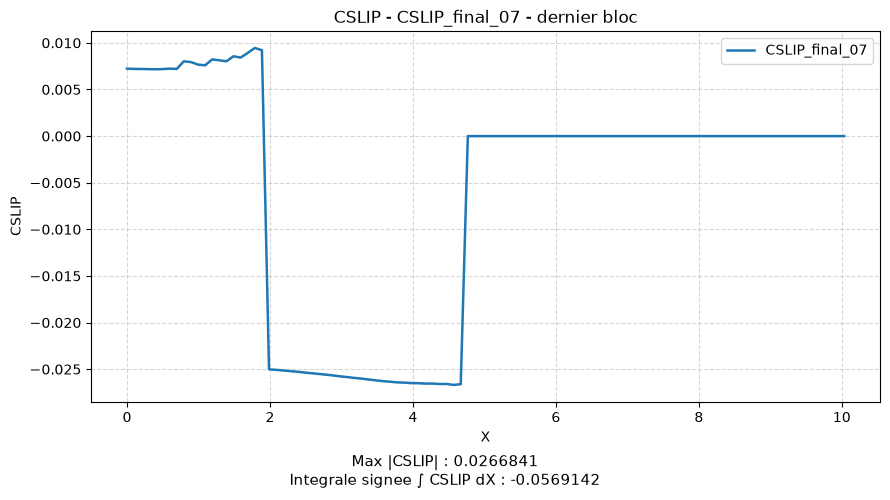

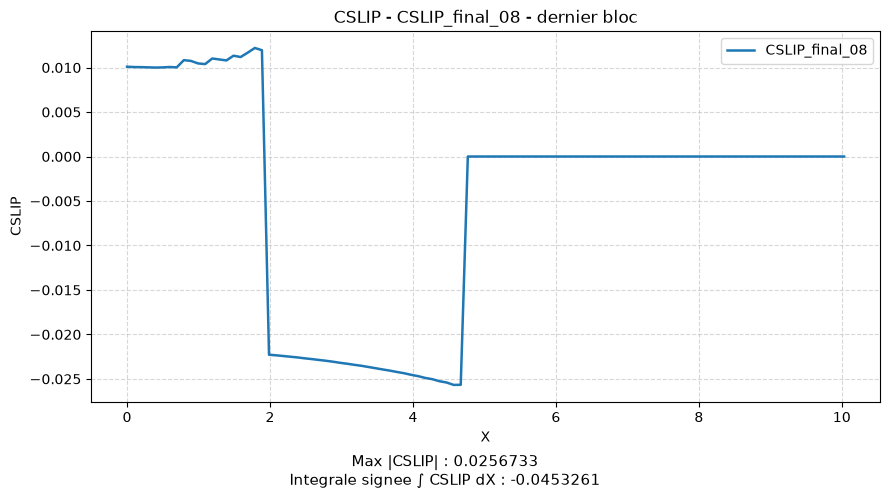

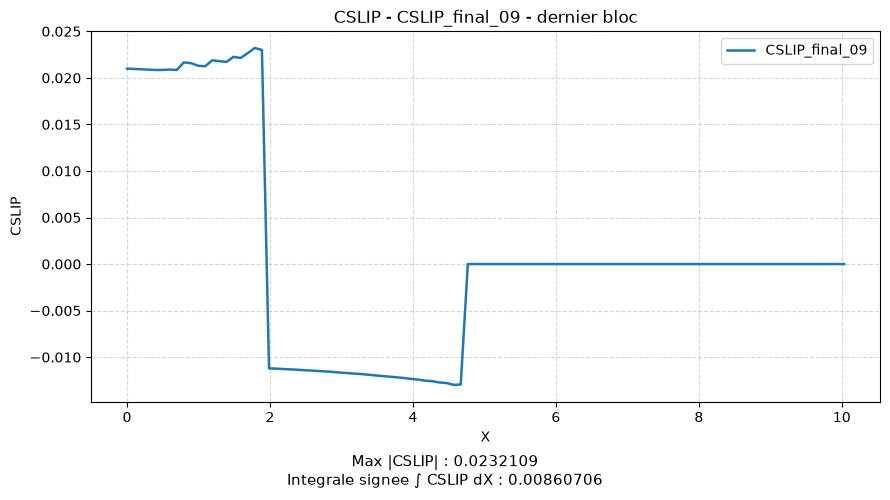

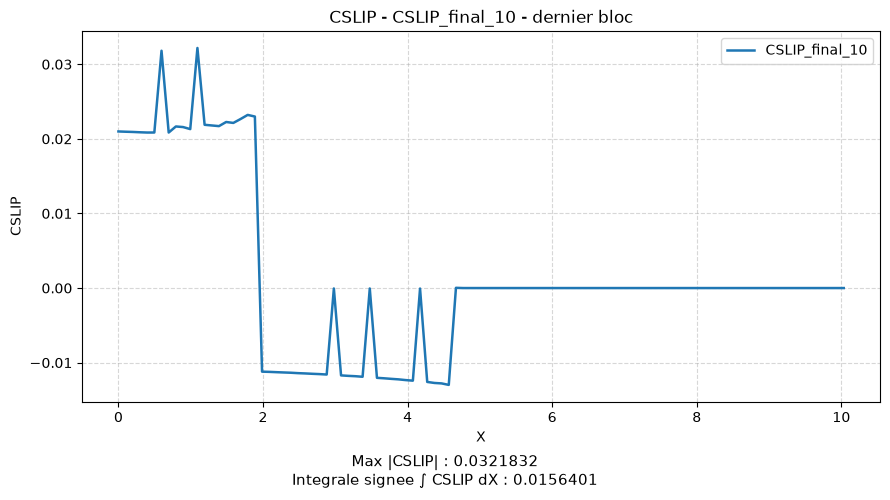

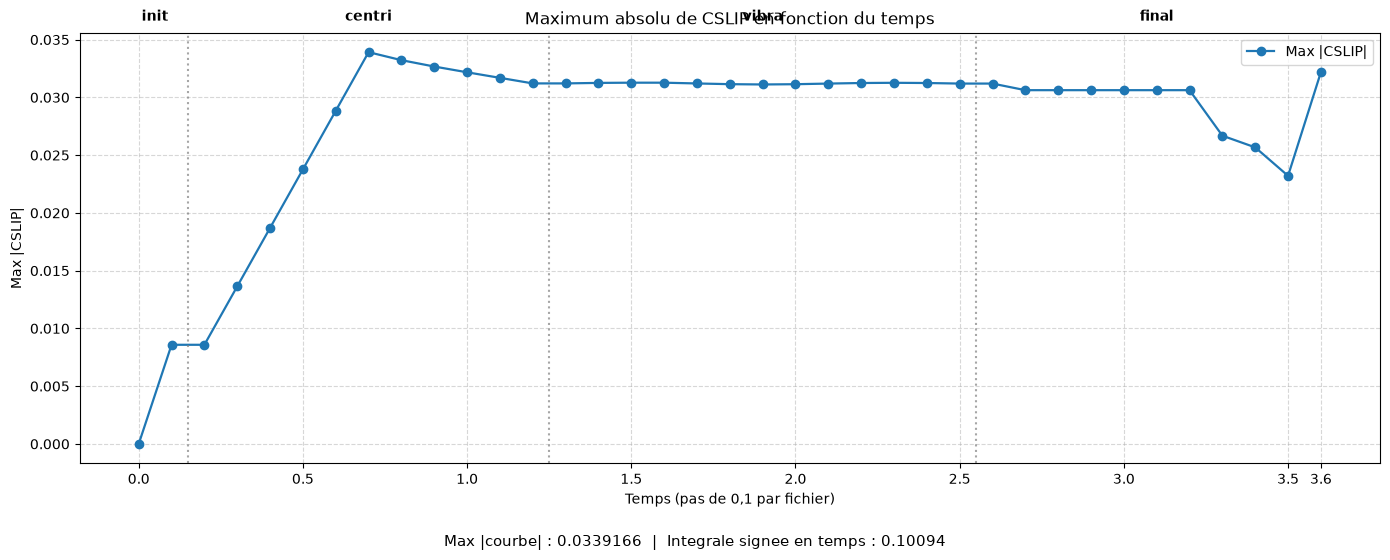

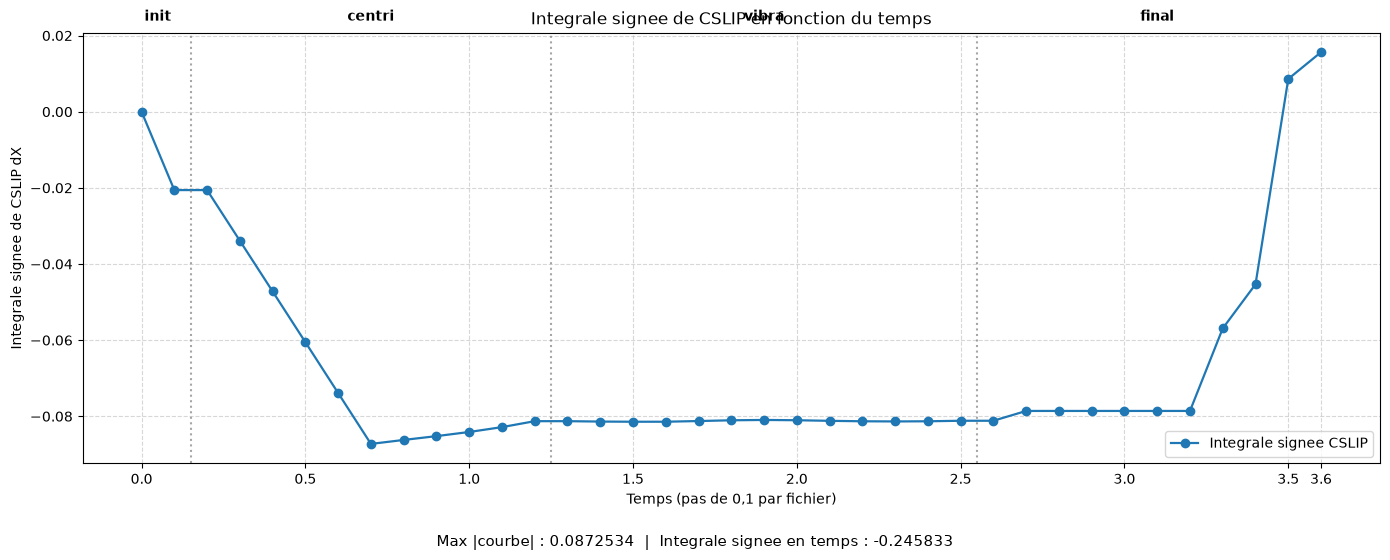

In [14]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


# Choisir ici la grandeur a tracer.
GRANDEUR = "CSLIP"  # CSHEAR, CSLIP, CPRESS ou SIGMAF
GRANDEURS_DISPONIBLES = {"CSHEAR", "CSLIP", "CPRESS", "SIGMAF"}
if GRANDEUR not in GRANDEURS_DISPONIBLES:
    raise ValueError(f"Grandeur inconnue : {GRANDEUR}. Choix possibles : {sorted(GRANDEURS_DISPONIBLES)}")

racine = Path.cwd()
while not (racine / "Export" / GRANDEUR).is_dir() and racine.parent != racine:
    racine = racine.parent

DOSSIER_RPT = racine / "Export" / GRANDEUR
if not DOSSIER_RPT.is_dir():
    raise FileNotFoundError(f"Dossier {GRANDEUR} introuvable depuis {Path.cwd()}")
DOSSIER_SORTIE = DOSSIER_RPT / "graphiques_dernier_bloc"


def lire_blocs_rpt(chemin_fichier):
    """Lit les blocs numeriques separes par des en-tetes ou un retour de X."""
    blocs = []
    bloc_courant = []
    x_precedent = None

    with chemin_fichier.open("r", encoding="utf-8", errors="replace") as fichier:
        for ligne in fichier:
            morceaux = ligne.split()
            try:
                valeurs = [
                    float(morceau.replace("D", "E").replace("d", "e").replace(",", "."))
                    for morceau in morceaux
                ]
                if len(valeurs) < 2:
                    raise ValueError
            except ValueError:
                if bloc_courant:
                    blocs.append(np.asarray(bloc_courant, dtype=float))
                    bloc_courant = []
                    x_precedent = None
                continue

            if x_precedent is not None and valeurs[0] < x_precedent:
                blocs.append(np.asarray(bloc_courant, dtype=float))
                bloc_courant = []

            bloc_courant.append(valeurs)
            x_precedent = valeurs[0]

    if bloc_courant:
        blocs.append(np.asarray(bloc_courant, dtype=float))
    if not blocs:
        raise ValueError(f"Aucune donnee numerique trouvee dans {chemin_fichier}")
    return blocs


def tracer_courbes():
    ordre_categories = {"init": 0, "centri": 1, "vibra": 2, "final": 3}

    def cle_tri_fichier(fichier):
        elements = fichier.stem.split("_")
        if len(elements) < 3 or elements[-2] not in ordre_categories:
            raise ValueError(f"Nom de fichier non reconnu : {fichier.name}")
        try:
            numero = int(elements[-1])
        except ValueError as erreur:
            raise ValueError(f"Indice invalide dans {fichier.name}") from erreur
        return ordre_categories[elements[-2]], numero

    fichiers_rpt = sorted(DOSSIER_RPT.glob("*.rpt"), key=cle_tri_fichier)
    if not fichiers_rpt:
        raise FileNotFoundError(f"Aucun fichier .rpt trouve dans {DOSSIER_RPT}")

    DOSSIER_SORTIE.mkdir(parents=True, exist_ok=True)
    donnees = []

    for fichier in fichiers_rpt:
        blocs = lire_blocs_rpt(fichier)
        dernier_bloc = blocs[-1]
        donnees.append((fichier.stem, dernier_bloc))
        max_abs = float(np.max(np.abs(dernier_bloc[:, 1])))
        integrale_signee = float(np.trapezoid(dernier_bloc[:, 1], dernier_bloc[:, 0]))
        print(
            f"{fichier.name} : {len(blocs)} blocs, dernier bloc = "
            f"{len(dernier_bloc)} lignes, max |{GRANDEUR}| = {max_abs:.6g}, "
            f"integrale signee = {integrale_signee:.6g}"
        )

    maxima_absolus = {
        nom: float(np.max(np.abs(bloc[:, 1])))
        for nom, bloc in donnees
    }
    integrales_signees = {
        nom: float(np.trapezoid(bloc[:, 1], bloc[:, 0]))
        for nom, bloc in donnees
    }

    fig, ax = plt.subplots(figsize=(14, 8))
    for nom, bloc in donnees:
        ax.plot(bloc[:, 0], bloc[:, 1], label=nom, linewidth=1.2)
    ax.set(
        title=f"{GRANDEUR} - dernier bloc de chaque fichier",
        xlabel="X",
        ylabel=GRANDEUR,
    )
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(fontsize=8, ncol=2)
    fig.text(
        0.5,
        0.02,
        f"Maximum absolu global de {GRANDEUR} : {max(maxima_absolus.values()):.6g}",
        ha="center",
        fontsize=11,
    )
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig(DOSSIER_SORTIE / f"{GRANDEUR}_toutes_les_courbes.png", dpi=200)
    plt.show()
    plt.close(fig)

    for nom, bloc in donnees:
        fig, ax = plt.subplots(figsize=(9, 5))
        max_abs = maxima_absolus[nom]
        ax.plot(bloc[:, 0], bloc[:, 1], label=nom, linewidth=1.8)
        ax.set(
            title=f"{GRANDEUR} - {nom} - dernier bloc",
            xlabel="X",
            ylabel=GRANDEUR,
        )
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.legend()
        fig.text(
            0.5,
            0.02,
            f"Max |{GRANDEUR}| : {max_abs:.6g}\n"
            f"Integrale signee ∫ {GRANDEUR} dX : {integrales_signees[nom]:.6g}",
            ha="center",
            fontsize=11,
        )
        fig.tight_layout(rect=(0, 0.07, 1, 1))
        fig.savefig(DOSSIER_SORTIE / f"{nom}_dernier_bloc.png", dpi=200)
        plt.show()
        plt.close(fig)


    temps = np.arange(len(donnees), dtype=float) * 0.1
    categories = [nom.split("_")[-2] for nom, _ in donnees]

    def tracer_evolution_temporelle(valeurs, titre, label_y, nom_image, label):
        fig, ax = plt.subplots(figsize=(14, 6))
        ax.plot(temps, valeurs, marker="o", linewidth=1.6, label=label)
        ax.set(
            title=titre,
            xlabel="Temps (pas de 0,1 par fichier)",
            ylabel=label_y,
        )
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.legend()

        debut_groupe = 0
        for index in range(1, len(categories) + 1):
            if index == len(categories) or categories[index] != categories[debut_groupe]:
                centre = (temps[debut_groupe] + temps[index - 1]) / 2
                ax.text(
                    centre,
                    1.02,
                    categories[debut_groupe],
                    transform=ax.get_xaxis_transform(),
                    ha="center",
                    va="bottom",
                    fontweight="bold",
                    clip_on=False,
                )
                if index < len(categories):
                    limite = (temps[index - 1] + temps[index]) / 2
                    ax.axvline(limite, color="gray", linestyle=":", alpha=0.7)
                debut_groupe = index

        graduations = list(temps[::5])
        if not np.isclose(graduations[-1], temps[-1]):
            graduations.append(temps[-1])
        ax.set_xticks(graduations)

        aire_temporelle = float(np.trapezoid(valeurs, temps))
        fig.text(
            0.5,
            0.02,
            f"Max |courbe| : {np.max(np.abs(valeurs)):.6g}  |  "
            f"Integrale signee en temps : {aire_temporelle:.6g}",
            ha="center",
            fontsize=11,
        )
        fig.tight_layout(rect=(0, 0.06, 1, 0.94))
        fig.savefig(DOSSIER_SORTIE / nom_image, dpi=200)
        plt.show()
        plt.close(fig)

    valeurs_max = np.array([maxima_absolus[nom] for nom, _ in donnees])
    valeurs_integrales = np.array([integrales_signees[nom] for nom, _ in donnees])

    tracer_evolution_temporelle(
        valeurs_max,
        f"Maximum absolu de {GRANDEUR} en fonction du temps",
        f"Max |{GRANDEUR}|",
        f"{GRANDEUR}_max_absolu_en_fonction_du_temps.png",
        f"Max |{GRANDEUR}|",
    )
    tracer_evolution_temporelle(
        valeurs_integrales,
        f"Integrale signee de {GRANDEUR} en fonction du temps",
        f"Integrale signee de {GRANDEUR} dX",
        f"{GRANDEUR}_integrale_signee_en_fonction_du_temps.png",
        f"Integrale signee {GRANDEUR}",
    )

    return temps, categories, valeurs_integrales

temps, categories, valeurs_integrales = tracer_courbes()

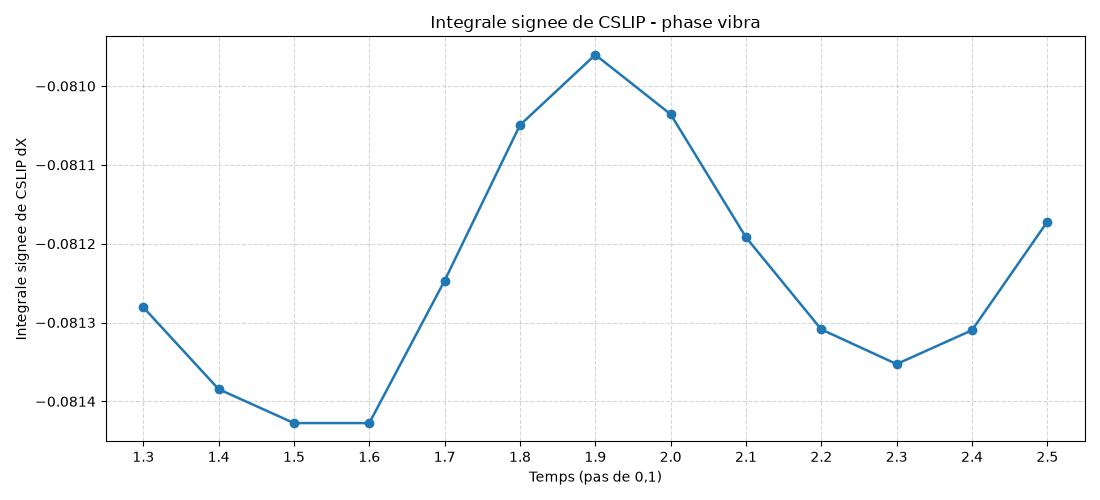

In [15]:
%matplotlib widget

indices_vibra = [i for i, categorie in enumerate(categories) if categorie == "vibra"]
if not indices_vibra:
    raise ValueError("Aucun point de la phase vibra n'a ete trouve.")

temps_vibra = temps[indices_vibra]
integrales_vibra = valeurs_integrales[indices_vibra]

fig_vibra, ax_vibra = plt.subplots(figsize=(11, 5))
ax_vibra.plot(temps_vibra, integrales_vibra, marker="o", linewidth=1.8)
ax_vibra.set_title(f"Integrale signee de {GRANDEUR} - phase vibra")
ax_vibra.set_xlabel("Temps (pas de 0,1)")
ax_vibra.set_ylabel(f"Integrale signee de {GRANDEUR} dX")
ax_vibra.set_xlim(temps_vibra[0] - 0.05, temps_vibra[-1] + 0.05)
ax_vibra.set_xticks(temps_vibra)
ax_vibra.grid(True, linestyle="--", alpha=0.5)
fig_vibra.tight_layout()
plt.show()